# Router Before the LLM: submission notebook

A cost-aware intent router for a personal finance assistant. This notebook is thin on purpose: it imports from `src/router/` and calls functions, so the same code runs here, in `scripts/` and in the demo.

**How to run:** Restart and Run All. With `FAST = True` (the default) it needs no GPU, no API key and no paid call. Numbers computed in fast mode are labelled as fast-mode numbers. The reported results are loaded from `results/`, where the scripts wrote them.

Sections follow the marking rubric: problem, data and preprocessing, models, evaluation, router and cost, limitations.

In [1]:
# Cell 1: environment.
# On Colab: clone the repo and install the pinned packages. Locally: nothing to install.
import os
import sys
from importlib.metadata import version

IN_COLAB = "google.colab" in sys.modules
REPO_URL = ""  # set once the GitHub repo exists (needed for the Colab clean-run check)

if IN_COLAB:
    import subprocess
    if not REPO_URL:
        raise RuntimeError("REPO_URL is not set yet, so the repo cannot be cloned on Colab.")
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "router-project"], check=True)
    os.chdir("router-project")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    sys.path.insert(0, os.path.abspath("src"))  # make `import router` work without a restart

print("Python", sys.version.split()[0])
for pkg in ["torch", "transformers", "datasets", "sentence-transformers", "scikit-learn", "pandas", "cleanlab"]:
    print(f"{pkg:>22} {version(pkg)}")

Python 3.12.4
                 torch 2.15.0
          transformers 5.24.0
              datasets 5.2.0
 sentence-transformers 6.3.0
          scikit-learn 1.9.1
                pandas 3.1.1
              cleanlab 2.9.0


In [2]:
# Cell 2: run mode and seeds.
FAST = True  # True: quick run, no GPU or API key needed. False: re-run the full five-seed scripts (Apple M3 Pro GPU, measured 22 Nov 2026: S1 30 min; E2 retrains S1 and S3 on cleaned labels in another 47 min).
SEED = 42

import time

from router.seed import pick_device, set_seed

set_seed(SEED)
NOTEBOOK_START = time.perf_counter()
print("FAST =", FAST, "| SEED =", SEED, "| device:", pick_device())

FAST = True | SEED = 42 | device: mps


## 1. Problem

A finance assistant sends every user query to an LLM, which costs money and time on each call. A small local model (the router) looks at each query first and either handles it directly, rejects it as out of scope, or escalates it to the LLM when unsure.

**Research question:** how many LLM calls can a small router safely remove, and at what error cost? The headline metric is coverage at matched risk: the largest share of queries the router can decide itself while its error rate stays at or below the LLM's.

## 2. Data and preprocessing

In-scope queries come from **Banking77** (Casanueva et al., 2020): 77 banking intents. Out-of-scope queries come from **CLINC150** (Larson et al., 2019). Both are loaded at a pinned Hub revision. Splits are created once by `scripts/make_splits.py` and saved to `data/processed/`, so every system sees the same data.

Pipeline (`src/router/preprocess.py`): unicode NFKC normalisation and whitespace cleanup, removal of empty rows and duplicates, a train/test leakage check, a stratified 10% validation split, token length checks and class balance. The full record is in `results/data_report.md`.

In [3]:
import json

import pandas as pd

from router import data

splits = {name: data.load_split(name) for name in data.SPLIT_FILES}
pd.DataFrame({"rows": {name: len(df) for name, df in splits.items()}})

,rows
train,8992
val,1000
test,3079
oos_val,350
oos_test,1000


In [4]:
# Rows removed at each step, per source (every removed row is listed in removed_rows.csv)
removed = pd.read_csv(data.PROCESSED_DIR / data.REMOVED_ROWS_FILE, keep_default_na=False)
removed.groupby(["source", "reason"]).size().unstack(fill_value=0)

reason,duplicate,leakage
source,,
banking77_test,1,0
banking77_train,4,7


In [5]:
# Token lengths per tokeniser, measured on train. max_length is used by S1 (and later S2, S3).
with open(data.PROCESSED_DIR / "token_lengths.json") as f:
    lengths = json.load(f)
pd.DataFrame(
    {
        name: {
            "p50": v["single"]["p50"],
            "p99": v["single"]["p99"],
            "max": v["single"]["max"],
            "max_length": v["single"]["max_length"],
            "test truncated": f"{v['truncated_share']['test']:.2%}",
            "pair max_length (S3)": v["pair"]["max_length"],
        }
        for name, v in lengths.items()
    }
).T

,p50,p99,max,max_length,test truncated,pair max_length (S3)
distilbert/distilroberta-base,13.0,50.09,93,56,0.29%,80
microsoft/deberta-v3-small,13.0,52.0,98,56,0.39%,80
sentence-transformers/all-MiniLM-L6-v2,13.0,53.0,98,56,0.39%,80


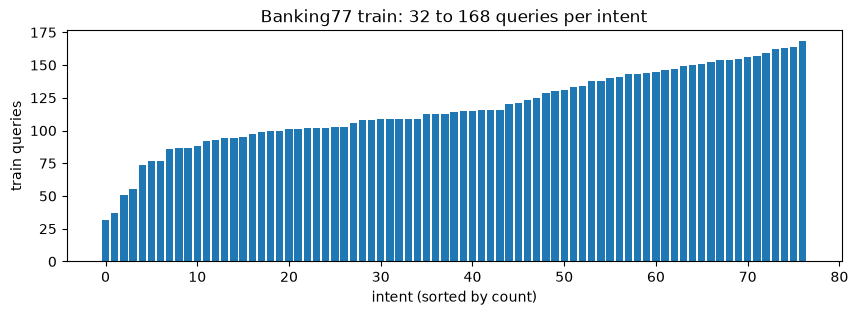

In [6]:
# Class balance: queries per intent in train. Uneven counts are why macro averages are primary.
import matplotlib.pyplot as plt

counts = splits["train"]["label"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(range(len(counts)), counts.values)
ax.set_xlabel("intent (sorted by count)")
ax.set_ylabel("train queries")
ax.set_title(f"Banking77 train: {counts.min()} to {counts.max()} queries per intent")
plt.show()

## 3. Models

Every system returns the same three things per query: a predicted intent, an in-scope confidence and an out-of-scope score (1 minus that confidence). That shared interface (`src/router/systems/base.py`, and `registry.load_predictor`, which turns any trained system into one function from texts to predictions) is what makes the comparison fair.

- **S0, TF-IDF + logistic regression** (`s0_tfidf.py`): the cheapest possible baseline. It shows how much of the task keywords alone can solve. Its n-gram range and regularisation strength were chosen on validation macro-F1 (`results/s0_grid.json`).
- **S1, fine-tuned DistilRoBERTa** (`s1_encoder.py`): the standard approach for this topic. A small pretrained encoder with a softmax head, fine-tuned for 5 epochs with fixed, standard hyperparameters. Confidence is the maximum softmax probability. DeBERTa-v3-small was the other candidate but could not be trained on the available hardware (`results/s1_selection.json`).
- **S2, embedding nearest neighbour** (`s2_embedding.py`): a frozen sentence-embedding model (all-MiniLM-L6-v2, chosen over MPNet in `results/s2_selection.json`). Each intent scores the cosine similarity of its closest train example; that similarity is the confidence. No training, and a new intent is added by adding examples. It is also S3's retriever.
- **S3, pairwise paraphrase matcher** (`s3_pairwise.py`), the main system: a cross-encoder asks "do these two queries mean the same thing?" for the query and each of 20 examples shortlisted by S2, and the best pair wins. Confidence is that pair's probability, and the matched example explains the decision. It starts from a paraphrase model (Quora question pairs) and is fine-tuned on pairs from the train split.

S4, the LLM the router is meant to call less often, is described in section 5.

In [7]:
# FAST = False: re-run the same scripts that produced the reported results.
import subprocess

if not FAST:
    for command in [
        ["scripts/train.py", "--system", "s0"],
        ["scripts/train.py", "--system", "s1"],
        ["scripts/train.py", "--system", "s2"],
        ["scripts/train.py", "--system", "s3"],
        ["scripts/evaluate.py", "--split", "val"],
        ["scripts/predict_format_control.py", "--split", "val"],
        ["scripts/run_s4.py", "--split", "val"],  # reads the committed S4 cache: no API call, no AWS account needed
        ["scripts/run_s4.py", "--split", "val", "--config", "s4_llm_fewshot"],
        ["scripts/evaluate.py", "--split", "val_fmt"],
        ["scripts/evaluate_oos.py", "--split", "val"],
        ["scripts/evaluate_oos.py", "--split", "val_fmt"],
        ["scripts/evaluate_router.py", "--split", "val_fmt"],
        # E2 (section 4c): flag label issues, retrain every system without them, compare.
        ["scripts/find_label_issues.py"],  # never replaces an audit sheet the owner has started
        ["scripts/train.py", "--system", "s0", "--labels", "cleaned"],
        ["scripts/train.py", "--system", "s1", "--labels", "cleaned"],
        ["scripts/train.py", "--system", "s2", "--labels", "cleaned"],
        ["scripts/train.py", "--system", "s3", "--labels", "cleaned"],
        ["scripts/evaluate_label_noise.py", "--split", "val"],
    ]:
        subprocess.run([sys.executable, *command], cwd=data.PROJECT_ROOT, check=True)
else:
    print("FAST mode: skipping the full five-seed re-run; reported results are loaded from results/.")

FAST mode: skipping the full five-seed re-run; reported results are loaded from results/.


In [8]:
# S0: train with the parameters chosen on validation, then predict the validation set.
from router.systems import s0_tfidf, s1_encoder
from router.systems.base import label_names_in_id_order

label_names = label_names_in_id_order()
train_df = splits["train"]
val_in_scope = splits["val"]  # E1 scores in-scope queries only

s0_cfg = data.load_config("s0_tfidf")
with open(data.RESULTS_DIR / "s0_grid.json") as f:
    s0_params = json.load(f)["chosen"]

start = time.perf_counter()
s0_model = s0_tfidf.train(train_df, s0_params, s0_cfg, seed=s0_cfg["seeds"][0])
s0_preds = s0_tfidf.predict(s0_model, val_in_scope["text"].tolist(), label_names)
print(f"S0 {s0_params}: trained and predicted in {time.perf_counter() - start:.1f}s")

/Users/krishilparmar/Developer/NLP_PROJECTS/INDIVIDUAL_PROJECT/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


S0 {'ngram_range': [1, 2], 'C': 100}: trained and predicted in 6.0s


In [9]:
# S1: load the saved seed-0 checkpoint if this machine has it; otherwise train briefly (fast mode).
s1_cfg = data.load_config("s1_encoder")
checkpoint = s1_cfg["checkpoint"]
device = pick_device()
max_length = s1_encoder.max_length_for(checkpoint)
saved = data.PROJECT_ROOT / "checkpoints" / "s1" / s1_encoder.system_tag(checkpoint) / "seed0"

start = time.perf_counter()
if saved.exists():
    s1_model, s1_tokenizer = s1_encoder.load(saved, device)
    s1_source = "saved seed-0 checkpoint"
else:
    steps = s1_cfg["fast_steps"]
    s1_model, s1_tokenizer, _ = s1_encoder.train(train_df, s1_cfg, checkpoint, seed=0, device=device, label_names=label_names, max_steps=steps)
    s1_source = f"trained here for {steps} steps only (no checkpoint on this machine)"
s1_preds = s1_encoder.predict(s1_model, s1_tokenizer, val_in_scope["text"].tolist(), label_names, device, max_length)
print(f"S1 {checkpoint} ({s1_source}) on {device}: {time.perf_counter() - start:.1f}s")

W1123 17:28:20.922000 13002 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 7115.19it/s]

S1 distilbert/distilroberta-base (saved seed-0 checkpoint) on mps: 4.0s


In [10]:
# S2: no training. Embed the train split (cached after the first run) and match each query to its nearest example.
from router.systems import s2_embedding, s3_pairwise
from router.systems.registry import s2_support_set, s3_max_length

s2_cfg = data.load_config("s2_embedding")
start = time.perf_counter()
encoder = s2_embedding.load_encoder(s2_cfg["checkpoint"], device)
support = s2_support_set(encoder, s2_cfg["checkpoint"], s2_cfg["batch_size"])
s2_preds = s2_embedding.predict(encoder, support, val_in_scope["text"].tolist(), label_names, s2_cfg["batch_size"])
print(f"S2 {s2_cfg['checkpoint']} on {device}: {time.perf_counter() - start:.1f}s")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1340.56it/s]

S2 sentence-transformers/all-MiniLM-L6-v2 on mps: 2.2s


In [11]:
# S3: load the saved seed-0 checkpoint if this machine has it; otherwise use the paraphrase
# model without any fine-tuning (fast mode), which still works because it already knows paraphrases.
s3_cfg = data.load_config("s3_pairwise")
s3_saved = data.PROJECT_ROOT / "checkpoints" / "s3" / s3_pairwise.system_tag(s3_cfg["checkpoint"]) / "seed0"
start = time.perf_counter()
if s3_saved.exists():
    s3_model, s3_tokenizer = s3_pairwise.load(s3_saved, device)
    s3_source = "saved seed-0 checkpoint"
else:
    s3_model, s3_tokenizer = s3_pairwise.load_base(s3_cfg["checkpoint"])
    s3_model.to(device)
    s3_source = "paraphrase model without fine-tuning (no checkpoint on this machine)"
s3_preds = s3_pairwise.predict(s3_model, s3_tokenizer, encoder, support, val_in_scope["text"].tolist(), label_names, s3_cfg, device, s3_max_length(s3_cfg))
print(f"S3 {s3_cfg['checkpoint']} ({s3_source}) on {device}: {time.perf_counter() - start:.1f}s")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 2394.53it/s]

S3 cross-encoder/quora-distilroberta-base (saved seed-0 checkpoint) on mps: 38.5s


In [12]:
# Why S3 decides what it decides: each prediction comes with the labelled example it matched.
pd.DataFrame({
    "query": val_in_scope["text"].head(6).values,
    "true intent": val_in_scope["label"].head(6).values,
    "S3 intent": s3_preds.pred_label[:6],
    "pair probability": s3_preds.confidence[:6].round(3),
    "matched example": s3_preds.matched_example[:6],
})

,query,true intent,S3 intent,pair probability,matched example
0,When did you send me my new card?,card_arrival,card_arrival,0.380,When will I get my new card?
1,Has my card been lost in delivery?,card_arrival,card_arrival,0.990,Is my card lost? I am still waiting for it to ...
2,My card still hasn't been delivered,card_arrival,card_arrival,0.960,My card hasn't arrived.
3,Can you tell me why I haven't received my new ...,card_arrival,card_arrival,0.998,Can you tell me why I haven't received my new ...
4,What's the reason my new card hasn't come?,card_arrival,card_arrival,0.993,Why has my new card still not come?
5,I am still waiting for my card.,card_arrival,card_arrival,0.998,I'm still waiting for my card.


## 4. Evaluation

E1 scores in-scope intent classification with accuracy, precision, recall and F1 (`src/router/metrics.py`, built on scikit-learn). Macro averages are primary because each of the 77 intents should count equally. Weighted averages are shown next to them.

**Sections 4 and 5 are validation numbers**, the ones every choice was made on. The test numbers, computed once after the pre-registration, are in section 6.

First, the numbers computed in this run (fast mode):

In [13]:
from router.metrics import classification_metrics

METRIC_ORDER = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_precision", "weighted_recall", "weighted_f1"]
fast_rows = {
    "S0 (this run)": classification_metrics(val_in_scope["label"], s0_preds.pred_label, labels=label_names),
    f"S1 ({s1_source})": classification_metrics(val_in_scope["label"], s1_preds.pred_label, labels=label_names),
    "S2 (this run)": classification_metrics(val_in_scope["label"], s2_preds.pred_label, labels=label_names),
    f"S3 ({s3_source})": classification_metrics(val_in_scope["label"], s3_preds.pred_label, labels=label_names),
}
(pd.DataFrame(fast_rows).T[METRIC_ORDER] * 100).round(2)

,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
S0 (this run),89.1,89.98,89.03,88.95,89.86,89.1,89.01
S1 (saved seed-0 checkpoint),91.7,92.69,92.06,92.10,92.23,91.7,91.68
S2 (this run),91.8,92.66,92.24,92.11,92.44,91.8,91.78
S3 (saved seed-0 checkpoint),89.9,90.64,90.41,90.08,90.74,89.9,89.92


**Reported results**: validation, mean ± standard deviation over five seeds, produced by `scripts/evaluate.py` (`results/e1_val.json`). S0 and S2 are deterministic, so their standard deviation is 0 (S2 runs once). Both S2 candidates are listed; S2 uses all-MiniLM-L6-v2.

About a quarter of validation queries have a near-paraphrase in train (cosine ≥ 0.95, `results/near_duplicates.md`), which favours nearest-neighbour systems like S2. Test has a similar rate, so validation remains a fair guide.

In [14]:
with open(data.RESULTS_DIR / "e1_val.json") as f:
    e1 = json.load(f)

reported = {
    tag: {k: f"{100 * r['summary'][k]['mean']:.2f} ± {100 * r['summary'][k]['std']:.2f}" for k in METRIC_ORDER}
    for tag, r in e1["systems"].items()
}
pd.DataFrame(reported).T

,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
s0_tfidf,89.10 ± 0.00,89.98 ± 0.00,89.03 ± 0.00,88.95 ± 0.00,89.86 ± 0.00,89.10 ± 0.00,89.01 ± 0.00
s1_distilroberta-base,91.10 ± 0.47,92.07 ± 0.48,91.47 ± 0.41,91.46 ± 0.44,91.62 ± 0.49,91.10 ± 0.47,91.06 ± 0.49
s2_all-MiniLM-L6-v2,91.80 ± 0.00,92.66 ± 0.00,92.24 ± 0.00,92.11 ± 0.00,92.44 ± 0.00,91.80 ± 0.00,91.78 ± 0.00
s2_all-mpnet-base-v2,91.30 ± 0.00,92.22 ± 0.00,91.66 ± 0.00,91.49 ± 0.00,92.01 ± 0.00,91.30 ± 0.00,91.21 ± 0.00
s3_quora-distilroberta-base,90.22 ± 0.26,91.17 ± 0.37,90.69 ± 0.22,90.52 ± 0.31,91.03 ± 0.21,90.22 ± 0.26,90.23 ± 0.26


In [15]:
# Where S1 struggles: the 10 intents with the lowest F1 and the most frequent confusions (validation, all seeds).
s1_tag = s1_encoder.system_tag(checkpoint)
worst = pd.DataFrame(e1["systems"][s1_tag]["worst_intents"]).set_index("intent").round(3)
confused = pd.DataFrame(e1["systems"][s1_tag]["top_confused_pairs"])
display(worst)
display(confused)

,precision,recall,f1,support
intent,,,,
topping_up_by_card,0.695,0.760,0.724,10.0
pending_top_up,0.780,0.707,0.741,15.0
transfer_not_received_by_recipient,0.879,0.671,0.760,17.0
balance_not_updated_after_bank_transfer,0.776,0.800,0.787,17.0
pin_blocked,0.838,0.745,0.789,11.0
top_up_by_bank_transfer_charge,0.978,0.727,0.834,11.0
why_verify_identity,0.861,0.817,0.835,12.0
declined_transfer,0.897,0.785,0.836,13.0
pending_transfer,0.806,0.880,0.841,15.0


,true,predicted,count
0,pending_top_up,top_up_failed,13
1,card_payment_wrong_exchange_rate,wrong_exchange_rate_for_cash_withdrawal,11
2,transfer_not_received_by_recipient,balance_not_updated_after_bank_transfer,11
3,why_verify_identity,verify_my_identity,11
4,declined_transfer,failed_transfer,10
5,top_up_by_bank_transfer_charge,top_up_by_card_charge,10
6,wrong_exchange_rate_for_cash_withdrawal,card_payment_wrong_exchange_rate,10
7,balance_not_updated_after_bank_transfer,pending_transfer,9
8,pin_blocked,change_pin,9
9,card_payment_not_recognised,direct_debit_payment_not_recognised,8


### 4b. Out-of-scope detection (E3)

A router must also notice queries it should not answer at all. Each system's out-of-scope score (1 minus its confidence) is checked on the mixed validation set: 1,000 Banking77 queries plus 350 CLINC150 out-of-scope queries (`scripts/evaluate_oos.py`).

- **AUROC:** the chance that a random out-of-scope query scores higher than a random in-scope one. Higher is better; 50 is a coin flip.
- **FPR at 95% TPR:** keep 95% of in-scope queries; the share of out-of-scope queries that are still let through. Lower is better.

**Format control.** Every CLINC150 query is lowercase with no punctuation, while most Banking77 queries are capitalised and punctuated, so formatting alone almost separates the two (the surface-cue table below). Every query, in-scope and out-of-scope alike, is therefore lowercased and stripped of punctuation before scoring (`router.preprocess.format_control`). These format-controlled numbers are the primary ones. The models themselves are unchanged.

First, this run (fast mode):

In [16]:
# E3 in this run: predict the mixed validation set (in-scope + out-of-scope) on format-controlled text.
from router.metrics import fpr_at_tpr, oos_auroc
from router.preprocess import format_control

val_mixed = data.load_eval_set("val", with_oos=True)
controlled_texts = val_mixed["text"].map(format_control).tolist()
is_oos = val_mixed["is_oos"].to_numpy(dtype=bool)

start = time.perf_counter()
fast_oos = {
    "S0 (this run)": s0_tfidf.predict(s0_model, controlled_texts, label_names),
    f"S1 ({s1_source})": s1_encoder.predict(s1_model, s1_tokenizer, controlled_texts, label_names, device, max_length),
    "S2 (this run)": s2_embedding.predict(encoder, support, controlled_texts, label_names, s2_cfg["batch_size"]),
    f"S3 ({s3_source})": s3_pairwise.predict(s3_model, s3_tokenizer, encoder, support, controlled_texts, label_names, s3_cfg, device, s3_max_length(s3_cfg)),
}
print(f"{len(controlled_texts)} queries ({is_oos.sum()} out of scope) scored by four systems in {time.perf_counter() - start:.1f}s")
pd.DataFrame({
    name: {"AUROC": 100 * oos_auroc(is_oos, p.oos_score), "FPR at 95% TPR": 100 * fpr_at_tpr(is_oos, p.oos_score)["fpr"]}
    for name, p in fast_oos.items()
}).T.round(2)

1350 queries (350 out of scope) scored by four systems in 51.4s


,AUROC,FPR at 95% TPR
S0 (this run),94.80,24.57
S1 (saved seed-0 checkpoint),96.82,20.00
S2 (this run),99.91,0.57
S3 (saved seed-0 checkpoint),99.68,0.86


**Reported results**: validation, format-controlled text, mean ± standard deviation over seeds (`results/e3_val_fmt.json`), with the raw-text AUROC next to it. The comparisons use a paired bootstrap (1,000 resamples of the same queries for both systems): when the 95% interval excludes 0, the difference is unlikely to be chance. RQ2 asks whether S3 beats S1 here (first row).

In [17]:
with open(data.RESULTS_DIR / "e3_val_fmt.json") as f:
    e3 = json.load(f)
with open(data.RESULTS_DIR / "e3_val.json") as f:
    e3_raw = json.load(f)


def mean_pm_std(summary: dict, key: str) -> str:
    return f"{100 * summary[key]['mean']:.2f} ± {100 * summary[key]['std']:.2f}"


display(pd.DataFrame({
    tag: {
        "AUROC": mean_pm_std(r["summary"], "auroc"),
        "FPR at 95% TPR": mean_pm_std(r["summary"], "fpr_at_tpr"),
        # S4 (the LLM) was only run on format-controlled text, to halve the API cost.
        "AUROC on raw text": mean_pm_std(e3_raw["systems"][tag]["summary"], "auroc") if tag in e3_raw["systems"] else "not run",
    }
    for tag, r in e3["systems"].items()
}).T)
display(pd.DataFrame([
    {"A": c["a"], "B": c["b"], "AUROC A - B (points)": round(100 * c["diff"], 2),
     "95% CI": f"[{100 * c['ci_low']:+.2f}, {100 * c['ci_high']:+.2f}]"}
    for c in e3["comparisons"]
]))

,AUROC,FPR at 95% TPR,AUROC on raw text
s0_tfidf,94.80 ± 0.00,24.57 ± 0.00,94.80 ± 0.00
s1_distilroberta-base,96.89 ± 0.09,18.23 ± 1.33,97.38 ± 0.10
s2_all-MiniLM-L6-v2,99.91 ± 0.00,0.57 ± 0.00,99.92 ± 0.00
s2_all-mpnet-base-v2,99.93 ± 0.00,0.29 ± 0.00,99.94 ± 0.00
s3_quora-distilroberta-base,99.72 ± 0.04,1.26 ± 0.38,99.70 ± 0.04
s4_claude-sonnet-4-6,99.04 ± 0.00,1.71 ± 0.00,not run
s4_claude-sonnet-4-6-fewshot,98.81 ± 0.00,2.29 ± 0.00,not run


,A,B,AUROC A - B (points),95% CI
0,s3_quora-distilroberta-base,s1_distilroberta-base,2.82,"[+2.21, +3.56]"
1,s3_quora-distilroberta-base,s2_all-MiniLM-L6-v2,-0.20,"[-0.33, -0.09]"
2,s3_quora-distilroberta-base,s0_tfidf,4.92,"[+3.70, +6.33]"


In [18]:
# Why the control is needed: each formatting rule on its own, with no model (AUROC; 50 = no signal).
pd.DataFrame({
    "raw text": {c["cue"]: round(100 * c["auroc"], 1) for c in e3_raw["surface_cues"]},
    "format-controlled text": {c["cue"]: round(100 * c["auroc"], 1) for c in e3["surface_cues"]},
})

,raw text,format-controlled text
starts lowercase,97.1,50.0
no final punctuation,93.3,50.0
no comma,56.5,50.0


The control also changes in-scope accuracy (`results/e1_val_fmt.json`), which doubles as a check on lowercase, unpunctuated input, the way people often type in a chat.

In [19]:
with open(data.RESULTS_DIR / "e1_val_fmt.json") as f:
    e1_fmt = json.load(f)
pd.DataFrame({
    tag: {"accuracy, raw text": mean_pm_std(e1["systems"][tag]["summary"], "accuracy") if tag in e1["systems"] else "not run",
          "accuracy, format-controlled": mean_pm_std(r["summary"], "accuracy")}
    for tag, r in e1_fmt["systems"].items()
}).T

,"accuracy, raw text","accuracy, format-controlled"
s0_tfidf,89.10 ± 0.00,89.10 ± 0.00
s1_distilroberta-base,91.10 ± 0.47,89.40 ± 1.01
s2_all-MiniLM-L6-v2,91.80 ± 0.00,90.80 ± 0.00
s2_all-mpnet-base-v2,91.30 ± 0.00,90.90 ± 0.00
s3_quora-distilroberta-base,90.22 ± 0.26,90.38 ± 0.26
s4_claude-sonnet-4-6,not run,76.30 ± 0.00
s4_claude-sonnet-4-6-fewshot,not run,84.30 ± 0.00


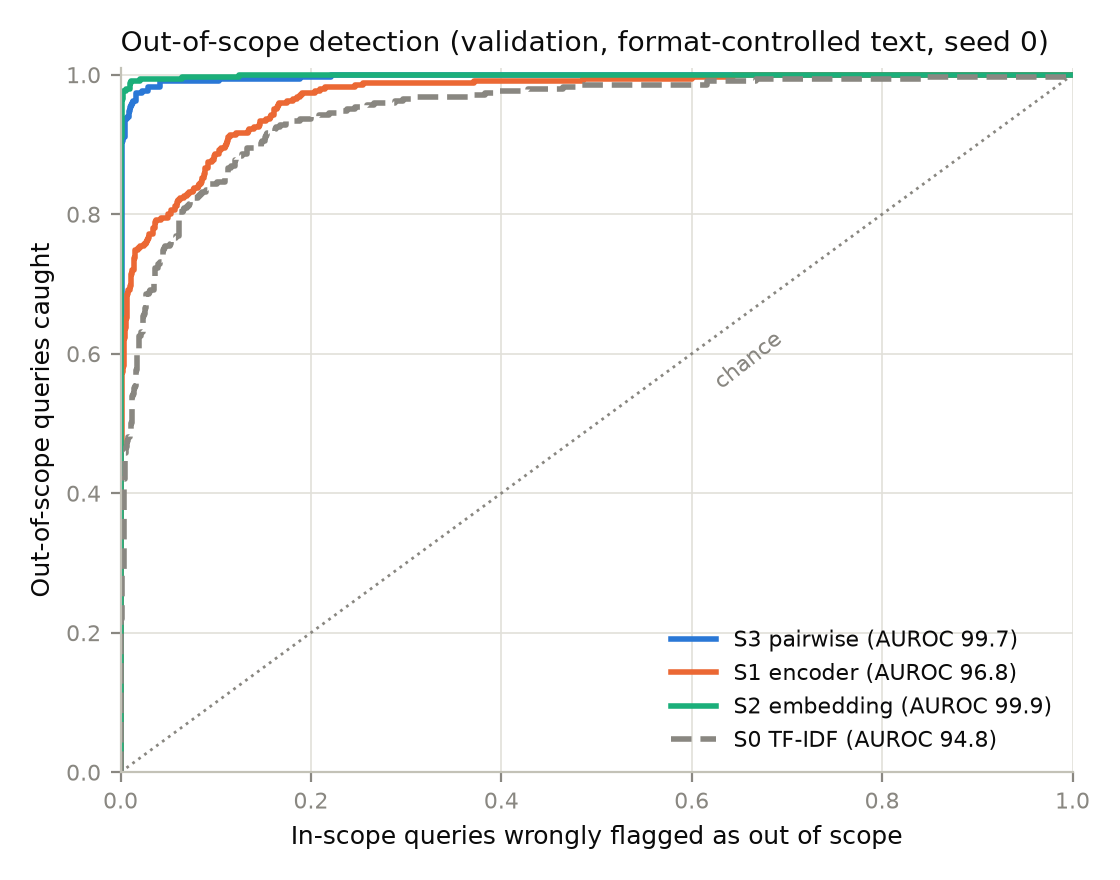

In [20]:
# ROC curves (seed 0 of each system), drawn by scripts/evaluate_oos.py.
from IPython.display import Image

Image(filename=str(data.PROJECT_ROOT / e3["figure"]), width=560)

In [21]:
# The out-of-scope queries S3 accepted most confidently (seed 0): the misses to read first.
pd.DataFrame(e3["most_confidently_accepted"]).round(3)

,text,pred_label,confidence,matched_example
0,can you tell me who else is on my account,topping_up_by_card,0.968,Can somebody else top up my account?
1,how do i change my billing address,edit_personal_details,0.954,My billing address changed and I need to updat...
2,which nations were on each side of the conflic...,country_support,0.850,Which countries are represented?
3,how do you store my card information,compromised_card,0.554,My card data has been exposed.
4,can you show me my credit card number,supported_cards_and_currencies,0.542,I need to know if you will accept my credit card.
5,what is the account number,cancel_transfer,0.540,I used the wrong account number!
6,can you restart my phone,lost_or_stolen_phone,0.421,I no longer have my phone.
7,what are the pros and cons of credit cards,supported_cards_and_currencies,0.409,What other credit cards can I use?
8,is the pnc bank open,change_pin,0.357,Can I change my PIN at my local bank?
9,are any earning reports due,receiving_money,0.311,Can my salary be received here?


### 4c. Label noise (E2)

Banking77 is known to contain labelling mistakes (Ying and Thomas, 2022). E2 asks whether they change this project's conclusions (RQ4: is the system ranking stable?).

- **Finding them:** cleanlab's confident learning (Northcutt et al., 2021). A separate model (frozen MPNet sentence embeddings plus logistic regression, not one of the compared systems) gives every train and validation query class probabilities from 5-fold cross-validation, so no query is scored by a model that saw its label. cleanlab flags the queries whose given label disagrees with those probabilities by more than the estimated noise rates allow (`scripts/find_label_issues.py`).
- **Cleaned** means the flagged queries are removed, never relabelled. Every system is retrained without the flagged train queries, with every other choice frozen, and scored with and without the flagged validation queries (`scripts/evaluate_label_noise.py`).
- **Flagged is not the same as wrong.** The owner hand-checks a random 100 flagged queries, blind to which label the dataset gave.

First, this run: re-derive the flags from the saved cross-validated probabilities (about a second).

In [22]:
# E2 in this run: cleanlab on the saved out-of-fold probabilities gives the same flags as the committed list.
import numpy as np

from router import label_noise

e2_cfg = data.load_config("e2_label_noise")
saved = np.load(data.PROCESSED_DIR / label_noise.PRED_PROBS_FILE)
ranked = label_noise.flag_issues(saved["label_id"], saved["pred_probs"], e2_cfg["cleanlab"]["filter_by"], e2_cfg["cleanlab"]["rank_by"], e2_cfg["cleanlab"]["n_jobs"])
flagged = label_noise.load_flagged()
same = len(ranked) == len(flagged) and bool((saved["source"][ranked] == flagged["source"].to_numpy()).all()) \
    and bool((saved["orig_index"][ranked] == flagged["orig_index"].to_numpy()).all())
print(f"{len(ranked)} of {len(saved['label_id'])} queries flagged "
      f"({(flagged['split'] == 'train').sum()} train, {(flagged['split'] == 'val').sum()} validation); "
      f"identical to data/processed/banking77_flagged.csv: {same}")
flagged.head(8)[["split", "text", "given_label", "suggested_label", "given_label_prob"]]

192 of 9992 queries flagged (163 train, 29 validation); identical to data/processed/banking77_flagged.csv: True


,split,text,given_label,suggested_label,given_label_prob
0,train,WHAT IS THE SOLUTION OF THIS PROBLEM,card_arrival,card_not_working,0.0000
1,val,i am not a premium customer but i want a virtu...,disposable_card_limits,getting_virtual_card,0.0000
2,val,what happened to the money after i put in the ...,topping_up_by_card,wrong_amount_of_cash_received,0.0000
3,train,Does the fee for exchange change?,card_payment_wrong_exchange_rate,exchange_charge,0.0000
4,train,Why did my payment get declined?,declined_transfer,declined_card_payment,0.0001
5,train,I'm trying to move money from my account to el...,declined_transfer,beneficiary_not_allowed,0.0001
6,train,Can you tell me the status of my new card?,lost_or_stolen_card,card_arrival,0.0001
7,train,how many days processing new card?,contactless_not_working,card_delivery_estimate,0.0001


**Reported results** (`results/e2_val.json`): in-scope macro-F1 on validation (raw text), mean ± standard deviation over seeds, in four cells: trained on original or cleaned labels, scored on all validation queries or with the flagged ones removed. The training effect uses a paired bootstrap stratified by intent (1,000 resamples).

In [23]:
with open(data.RESULTS_DIR / "e2_val.json") as f:
    e2 = json.load(f)
e2_cells = list(e2["rankings"])
display(pd.DataFrame({name: {cell: mean_pm_std(r["cells"][cell], "macro_f1") for cell in e2_cells} for name, r in e2["systems"].items()}).T)
print("Ranking stable in all four cells (RQ4):", e2["ranking_stable"])
for cell, order in e2["rankings"].items():
    print(f"  {cell}: {' > '.join(order)}")
display(pd.DataFrame([
    {"system": name, "cleaned - original macro-F1 (points)": round(100 * r["training_effect"]["diff"], 2),
     "95% CI": f"[{100 * r['training_effect']['ci_low']:+.2f}, {100 * r['training_effect']['ci_high']:+.2f}]"}
    for name, r in e2["systems"].items()
]))

,"original train, all","cleaned train, all","original train, flagged removed","cleaned train, flagged removed"
S0 TF-IDF,88.95 ± 0.00,87.76 ± 0.00,90.69 ± 0.00,89.70 ± 0.00
S1 encoder,91.46 ± 0.44,91.58 ± 0.61,93.65 ± 0.50,93.77 ± 0.56
S2 embedding,92.11 ± 0.00,92.65 ± 0.00,94.04 ± 0.00,94.53 ± 0.00
S3 pairwise,90.52 ± 0.31,91.30 ± 0.45,92.49 ± 0.30,93.25 ± 0.50


Ranking stable in all four cells (RQ4): True
  original train, all: S2 embedding > S1 encoder > S3 pairwise > S0 TF-IDF
  cleaned train, all: S2 embedding > S1 encoder > S3 pairwise > S0 TF-IDF
  original train, flagged removed: S2 embedding > S1 encoder > S3 pairwise > S0 TF-IDF
  cleaned train, flagged removed: S2 embedding > S1 encoder > S3 pairwise > S0 TF-IDF


,system,cleaned - original macro-F1 (points),95% CI
0,S0 TF-IDF,-1.19,"[-2.22, -0.12]"
1,S1 encoder,0.12,"[-0.39, +0.65]"
2,S2 embedding,0.54,"[+0.01, +1.13]"
3,S3 pairwise,0.79,"[+0.16, +1.48]"


In [24]:
# S4 is not retrained (it has no training data). Its error rate on the mixed set is E6's matched risk:
# how much of it comes from the flagged queries? (format-controlled text, cached replies, no API calls)
display(pd.DataFrame({
    s["name"]: {"error rate, all (%)": round(100 * s["all"]["error_rate"], 2),
                "error rate, flagged removed (%)": round(100 * s["flagged removed"]["error_rate"], 2)}
    for s in e2["s4_evaluation_effect"]
}).T)
audit = e2["audit"]
if audit and audit["complete"]:
    # Each annotator on their own items (owner, Claude judge), then all items together.
    for who, a in [*e2.get("audit_by_annotator", {}).items(), ("all items", audit)]:
        low, high = a["real_error_ci95"]
        print(f"Audit, {who}: {a['real_error']} of {a['n_items']} flagged queries are real label errors "
              f"(95% interval {100 * low:.0f} to {100 * high:.0f}%); ambiguous {a['ambiguous']}, false flags {a['false_flag']}.")
    agree = e2.get("audit_agreement")
    if agree:
        print(f"Owner and Claude judge on the same {agree['n_items']} items: same verdict {agree['same_verdict']}, "
              f"same scored category {agree['same_category']}.")
else:
    print("Audit: not finished yet" + (f" ({audit['n_done']} of {audit['n_items']} items done)." if audit else "."))

,"error rate, all (%)","error rate, flagged removed (%)"
S4 zero-shot,18.00,16.81
S4 few-shot,12.22,10.90


Audit, claude: 53 of 89 flagged queries are real label errors (95% interval 49 to 69%); ambiguous 9, false flags 27.
Audit, owner: 8 of 11 flagged queries are real label errors (95% interval 43 to 90%); ambiguous 1, false flags 2.
Audit, all items: 61 of 100 flagged queries are real label errors (95% interval 51 to 70%); ambiguous 10, false flags 29.
Owner and Claude judge on the same 11 items: same verdict 8, same scored category 8.


## 5. Router and cost (E6, the headline result)

The router answers a query itself (HANDLE) when its confidence is at or above a threshold, and sends the rest to the LLM (ESCALATE). The LLM is S4: Claude Sonnet 4.6 on Amazon Bedrock, the model the assistant runs today, given the 77 intent names zero-shot at temperature 0.

- **Matched risk:** S4's error rate on the same queries. Each router's threshold is the one that handles the most queries while being wrong on them no more often than S4 is.
- **Coverage:** the share of queries the router handles, so the share of LLM calls avoided.
- **Cost per query** = (1 - coverage) x S4's measured cost per call (the local router's own cost is taken as zero; its latency is shown below).

Everything uses the format-controlled validation set (in-scope plus out-of-scope). S4's replies are cached in `results/s4_cache/`, so this notebook never calls the API.

First, this run (fast mode, with the systems in memory and no temperature scaling):

In [25]:
import numpy as np

from router.metrics import aurc, coverage_at_risk, risk_coverage_curve
from router.systems.base import load_predictions

# Cached S4 replies (no API call), for both variants. The one with the lower error sets the matched risk.
s4_errors = {}
for tag in data.load_config("e6_router")["llm_systems"]:
    s4_preds, _ = load_predictions(tag, 0, "val_fmt")
    assert s4_preds["text"].tolist() == controlled_texts  # same queries, same order
    s4_errors[tag] = float((s4_preds["pred_label"] != s4_preds["label"]).mean())
    print(f"{tag}: error rate {100 * s4_errors[tag]:.2f}%")
s4_error = min(s4_errors.values())
true_labels = val_mixed["label"].to_numpy()
print(f"Matched risk on these {len(true_labels)} queries: {100 * s4_error:.2f}%")

fast_rows = {}
for name, p in fast_oos.items():
    correct = np.asarray(p.pred_label) == true_labels  # an out-of-scope query is never correct for S0-S3
    matched = coverage_at_risk(correct, p.confidence, s4_error)
    fast_rows[name] = {
        "coverage at matched risk (%)": 100 * matched["coverage"],
        "AURC (%)": 100 * aurc(risk_coverage_curve(correct, p.confidence)),
    }
pd.DataFrame(fast_rows).T.round(2)

s4_claude-sonnet-4-6: error rate 18.00%
s4_claude-sonnet-4-6-fewshot: error rate 12.22%
Matched risk on these 1350 queries: 12.22%


,coverage at matched risk (%),AURC (%)
S0 (this run),70.67,9.09
S1 (saved seed-0 checkpoint),74.15,7.32
S2 (this run),76.59,8.16
S3 (saved seed-0 checkpoint),76.07,7.77


**Reported results** (`scripts/evaluate_router.py`, `results/e6_val_fmt.json`): mean ± standard deviation over seeds, with S0 and S1 temperature-scaled on validation. "OOS handled" counts out-of-scope queries a router answered itself, the dangerous error. The thresholds and temperatures are frozen in `results/policy_v1.json` for the single test run.

In [26]:
with open(data.RESULTS_DIR / "e6_val_fmt.json") as f:
    e6 = json.load(f)
# Both S4 variants; the one with the lower error rate sets the matched risk (rule fixed before E6 ran).
display(pd.DataFrame({
    tag: {"error rate (%)": round(100 * v["error_rate"], 2), "in-scope accuracy (%)": round(100 * v["in_scope_accuracy"], 2),
          "OOS recall (%)": round(100 * v["oos_recall"], 2), "US$ per 1,000 queries": round(1000 * v["cost_per_call_usd"], 3)}
    for tag, v in e6["s4_variants"].items()
}).T)
s4 = e6["s4"]
print(f"Matched risk set by {e6['llm_system']}: error rate {100 * s4['error_rate']:.2f}%, "
      f"US${1000 * s4['cost_per_call_usd']:.3f} per 1,000 queries if every query goes to the LLM")
display(pd.DataFrame({
    tag: {
        "coverage at matched risk (%)": mean_pm_std(r["summary"], "coverage"),
        "selective risk (%)": mean_pm_std(r["summary"], "selective_risk"),
        "OOS handled": f"{r['summary']['oos_handled']['mean']:.1f}",
        "cost per 1,000 queries (US$)": f"{r['summary']['cost_per_1000_usd']['mean']:.3f}",
        "saving vs LLM only (%)": mean_pm_std(r["summary"], "saving_vs_llm"),
    }
    for tag, r in e6["systems"].items()
}).T)
print("Best router (highest mean coverage at matched risk):", e6["best_router"])
pd.DataFrame([
    {"A": c["a"], "B": c["b"], "coverage A - B (points)": round(100 * c["diff"], 2),
     "95% CI": f"[{100 * c['ci_low']:+.2f}, {100 * c['ci_high']:+.2f}]"}
    for c in e6["comparisons"]
])

,error rate (%),in-scope accuracy (%),OOS recall (%),"US$ per 1,000 queries"
s4_claude-sonnet-4-6,18.00,76.3,98.29,0.791
s4_claude-sonnet-4-6-fewshot,12.22,84.3,97.71,1.571


Matched risk set by s4_claude-sonnet-4-6-fewshot: error rate 12.22%, US$1.571 per 1,000 queries if every query goes to the LLM


,coverage at matched risk (%),selective risk (%),OOS handled,"cost per 1,000 queries (US$)",saving vs LLM only (%)
s0_tfidf,70.74 ± 0.00,12.15 ± 0.00,61.0,0.460,70.74 ± 0.00
s1_distilroberta-base,73.38 ± 0.64,12.17 ± 0.03,54.4,0.418,73.38 ± 0.64
s2_all-MiniLM-L6-v2,76.59 ± 0.00,12.19 ± 0.00,34.0,0.368,76.59 ± 0.00
s3_quora-distilroberta-base,76.18 ± 0.25,12.19 ± 0.02,31.6,0.374,76.18 ± 0.25


Best router (highest mean coverage at matched risk): s2_all-MiniLM-L6-v2


,A,B,coverage A - B (points),95% CI
0,s3_quora-distilroberta-base,s1_distilroberta-base,2.80,"[+0.92, +4.16]"
1,s3_quora-distilroberta-base,s2_all-MiniLM-L6-v2,-0.41,"[-1.72, +0.76]"


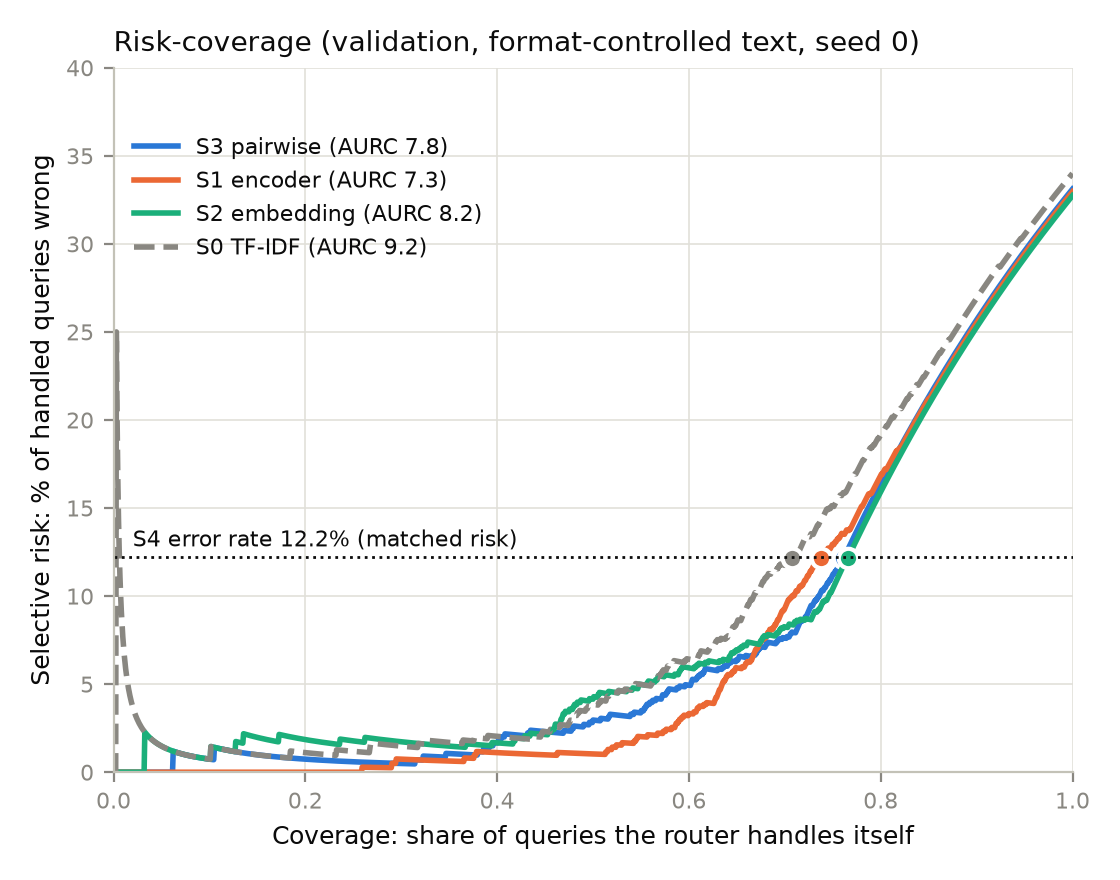

In [27]:
# Risk-coverage curves (seed 0); dots mark each router's matched-risk operating point.
Image(filename=str(data.PROJECT_ROOT / e6["figure"]), width=560)

In [28]:
# Latency per query on CPU (batch size 1, warm model), and S4's API latency for comparison.
latency_rows = {tag: {"p50 (ms)": round(v["p50_ms"], 1), "p95 (ms)": round(v["p95_ms"], 1)} for tag, v in e6["latency"]["systems"].items()}
latency_rows["S4 API (from Sydney)"] = {"p50 (ms)": round(s4["api_latency_ms"]["p50"]), "p95 (ms)": round(s4["api_latency_ms"]["p95"])}
print(e6["latency"]["machine"])
pd.DataFrame(latency_rows).T

Apple M3 Pro, CPU only, 5 torch threads


,p50 (ms),p95 (ms)
s0_tfidf,0.3,0.3
s1_distilroberta-base,14.4,18.9
s2_all-MiniLM-L6-v2,5.5,6.4
s3_quora-distilroberta-base,95.7,159.7
S4 API (from Sydney),682.0,831.0


## 6. Test results (M5, run once)

Every choice was frozen and the thresholds were pre-registered in `results/preregistration.md` before any test prediction existed (`git log` shows the order). Each test split was touched once per system. This section only reads the result files the scripts wrote; it never predicts on test.

**Verdicts** (`scripts/report_verdicts.py`, `results/verdicts.md`): each hypothesis against its pre-registered threshold. "Not clear-cut" means the 95% interval crosses the threshold.

In [29]:
with open(data.RESULTS_DIR / "verdicts.json") as f:
    verdicts = json.load(f)
pd.DataFrame(verdicts["verdicts"]).set_index("id")

,hypothesis,result,verdict
id,,,
RQ1,best router (s2_all-MiniLM-L6-v2) coverage at ...,"77.47% [76.44, 78.43] (matched risk 10.27%)",met
RQ2,S3 minus S1 OOS AUROC on test >= 1 point,"+3.08 points [+2.60, +3.61]",met
RQ3,S3 within 5 accuracy points of a retrained sof...,E4 not run,not tested
RQ4,system ranking stable between original and cle...,order S1 encoder > S2 embedding > S3 pairwise ...,met
RQ5,best router flip rate under paraphrase < 10% (E5),E5 not run,not tested
RQ6,coverage drop from Banking77 test to the Jeff ...,"+75.80 points: Banking77 77.47% [76.44, 78.43]...",not met
R4,best router p95 latency <= 100 ms (Apple M3 Pr...,p95 6.4 ms over 200 queries,met


**E1 on test** (raw text, in-scope queries, mean ± standard deviation over seeds, `results/e1_test.json`): the rubric's accuracy, precision, recall and F1.

In [30]:
with open(data.RESULTS_DIR / "e1_test.json") as f:
    e1_test = json.load(f)
pd.DataFrame({tag: {k: mean_pm_std(r["summary"], k) for k in METRIC_ORDER} for tag, r in e1_test["systems"].items()}).T

,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
s0_tfidf,89.09 ± 0.00,89.61 ± 0.00,89.09 ± 0.00,89.11 ± 0.00,89.61 ± 0.00,89.09 ± 0.00,89.11 ± 0.00
s1_distilroberta-base,93.14 ± 0.16,93.41 ± 0.16,93.14 ± 0.16,93.13 ± 0.17,93.40 ± 0.16,93.14 ± 0.16,93.13 ± 0.17
s2_all-MiniLM-L6-v2,91.98 ± 0.00,92.13 ± 0.00,91.98 ± 0.00,91.96 ± 0.00,92.13 ± 0.00,91.98 ± 0.00,91.96 ± 0.00
s3_quora-distilroberta-base,90.93 ± 0.22,91.08 ± 0.21,90.94 ± 0.22,90.89 ± 0.22,91.08 ± 0.21,90.93 ± 0.22,90.89 ± 0.22


**E6 on test** (format-controlled, `results/e6_test_fmt.json`). The matched risk is few-shot S4's error rate on the test queries. "Coverage at matched risk" is recomputed on test: the RQ1 number, with its bootstrap interval. The policy v1 columns apply the thresholds frozen on validation unchanged, which is what a deployed router would do.

In [31]:
with open(data.RESULTS_DIR / "e6_test_fmt.json") as f:
    e6_test = json.load(f)
s4_test = e6_test["s4"]
print(f"Matched risk ({e6_test['llm_system']} on test): {100 * s4_test['error_rate']:.2f}% | in-scope accuracy "
      f"{100 * s4_test['in_scope_accuracy']:.2f}%, OOS recall {100 * s4_test['oos_recall']:.2f}%, invalid replies {s4_test['invalid']}")
pd.DataFrame({
    tag: {"coverage at matched risk (%)": mean_pm_std(r["summary"], "coverage_at_matched_risk"),
          "95% CI": f"[{100 * r['coverage_at_matched_risk_ci']['ci_low']:.2f}, {100 * r['coverage_at_matched_risk_ci']['ci_high']:.2f}]",
          "policy v1 coverage (%)": mean_pm_std(r["summary"], "coverage"),
          "policy v1 selective risk (%)": mean_pm_std(r["summary"], "selective_risk"),
          "OOS handled": f"{r['summary']['oos_handled']['mean']:.1f}",
          "cost per 1,000 queries (US$)": f"{r['summary']['cost_per_1000_usd']['mean']:.3f}"}
    for tag, r in e6_test["systems"].items()
}).T

Matched risk (s4_claude-sonnet-4-6-fewshot on test): 10.27% | in-scope accuracy 87.17%, OOS recall 97.60%, invalid replies 0


,coverage at matched risk (%),95% CI,policy v1 coverage (%),policy v1 selective risk (%),OOS handled,"cost per 1,000 queries (US$)"
s0_tfidf,70.65 ± 0.00,"[68.84, 72.52]",72.32 ± 0.00,11.36 ± 0.00,162.0,0.437
s1_distilroberta-base,75.07 ± 0.20,"[73.78, 76.33]",75.37 ± 0.80,10.50 ± 0.68,172.4,0.389
s2_all-MiniLM-L6-v2,77.47 ± 0.00,"[76.44, 78.43]",78.11 ± 0.00,10.99 ± 0.00,109.0,0.346
s3_quora-distilroberta-base,75.71 ± 0.20,"[74.33, 76.94]",77.52 ± 0.43,12.02 ± 0.43,98.2,0.355


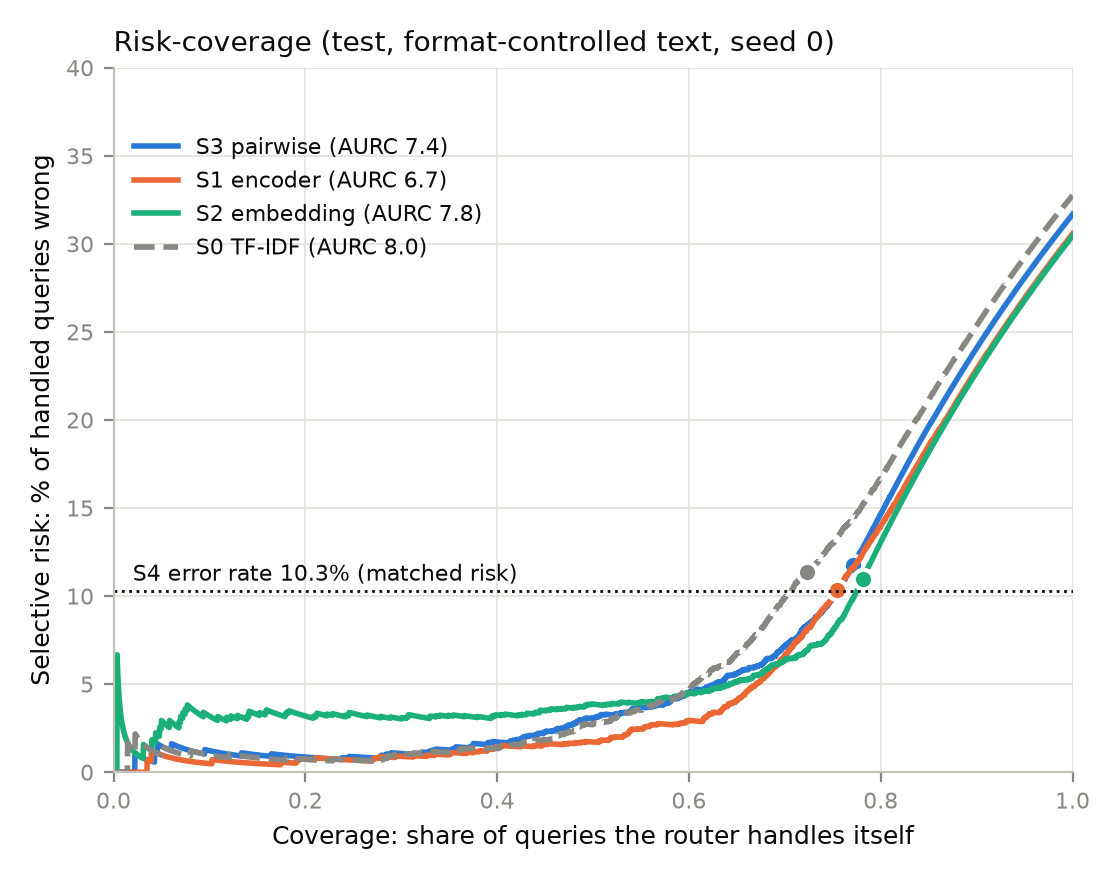

In [32]:
# Risk-coverage curves on test (seed 0); dots mark the policy v1 operating points (validation thresholds).
Image(filename=str(data.PROJECT_ROOT / e6_test["figure"]), width=560)

**E3 and E2 on test.** Out-of-scope detection on format-controlled test (`results/e3_test_fmt.json`, RQ2 is the first comparison), and the label-noise training effect on raw test (`results/e2_test.json`, RQ4): models trained on cleaned labels against the original ones, both scored on the original test labels.

In [33]:
with open(data.RESULTS_DIR / "e3_test_fmt.json") as f:
    e3_test = json.load(f)
display(pd.DataFrame({tag: {"AUROC": mean_pm_std(r["summary"], "auroc")} for tag, r in e3_test["systems"].items()}).T)
display(pd.DataFrame([{"A": c["a"], "B": c["b"], "AUROC A - B (points)": round(100 * c["diff"], 2),
                       "95% CI": f"[{100 * c['ci_low']:+.2f}, {100 * c['ci_high']:+.2f}]"} for c in e3_test["comparisons"]]))
with open(data.RESULTS_DIR / "e2_test.json") as f:
    e2_test = json.load(f)
print("Ranking stable between original and cleaned labels (RQ4):", e2_test["ranking_stable"])
pd.DataFrame([{"system": name, "cleaned - original macro-F1 (points)": round(100 * r["training_effect"]["diff"], 2),
               "95% CI": f"[{100 * r['training_effect']['ci_low']:+.2f}, {100 * r['training_effect']['ci_high']:+.2f}]"}
              for name, r in e2_test["systems"].items()])

,AUROC
s0_tfidf,95.54 ± 0.00
s1_distilroberta-base,96.40 ± 0.20
s2_all-MiniLM-L6-v2,99.70 ± 0.00
s3_quora-distilroberta-base,99.49 ± 0.00
s4_claude-sonnet-4-6-fewshot,98.65 ± 0.00


,A,B,AUROC A - B (points),95% CI
0,s3_quora-distilroberta-base,s1_distilroberta-base,3.08,"[+2.60, +3.61]"
1,s3_quora-distilroberta-base,s2_all-MiniLM-L6-v2,-0.21,"[-0.31, -0.13]"
2,s3_quora-distilroberta-base,s0_tfidf,3.95,"[+3.32, +4.60]"


Ranking stable between original and cleaned labels (RQ4): True


,system,cleaned - original macro-F1 (points),95% CI
0,S0 TF-IDF,-0.01,"[-0.38, +0.37]"
1,S1 encoder,-0.26,"[-0.50, -0.02]"
2,S2 embedding,0.28,"[-0.04, +0.61]"
3,S3 pairwise,0.30,"[-0.11, +0.74]"


**E7, the Jeff set** (`results/e7_jeff.json`, RQ6). 180 test queries for Jeff's 14 real intents plus 40 out of scope, written by a Claude agent (README 6.1). S2 and S3 use the 140 Jeff support queries as their support set with no retraining; S0 and S1 cannot output a Jeff intent. The matched risk is few-shot S4's error rate on these queries.

In [34]:
with open(data.RESULTS_DIR / "e7_jeff.json") as f:
    e7 = json.load(f)
print(f"Jeff test: {e7['n_queries']} queries ({e7['n_oos']} out of scope); matched risk: {100 * e7['matched_risk']:.2f}%")
display(pd.DataFrame({tag: {"error rate (%)": round(100 * v["error_rate"], 2), "in-scope accuracy (%)": round(100 * v["in_scope_accuracy"], 2),
                            "OOS recall (%)": round(100 * v["oos_recall"], 2)} for tag, v in e7["s4_variants"].items()}).T)
pd.DataFrame({
    tag: {"in-scope accuracy (%)": mean_pm_std(r["summary"], "in_scope_accuracy"),
          "OOS AUROC (%)": mean_pm_std(r["summary"], "oos_auroc"),
          "coverage at matched risk (%)": mean_pm_std(r["summary"], "coverage_at_matched_risk"),
          "95% CI": f"[{100 * r['coverage_at_matched_risk_ci']['ci_low']:.2f}, {100 * r['coverage_at_matched_risk_ci']['ci_high']:.2f}]",
          "coverage at frozen thresholds (%)": mean_pm_std(r["summary"], "coverage_frozen_threshold"),
          "selective risk there (%)": mean_pm_std(r["summary"], "selective_risk_frozen_threshold")}
    for tag, r in e7["systems"].items()
}).T

Jeff test: 180 queries (40 out of scope); matched risk: 0.56%


,error rate (%),in-scope accuracy (%),OOS recall (%)
s4_claude-sonnet-4-6,1.11,98.57,100.0
s4_claude-sonnet-4-6-fewshot,0.56,99.29,100.0


,in-scope accuracy (%),OOS AUROC (%),coverage at matched risk (%),95% CI,coverage at frozen thresholds (%),selective risk there (%)
s2_all-MiniLM-L6-v2,56.43 ± 0.00,90.93 ± 0.00,1.67 ± 0.00,"[0.00, 6.67]",61.67 ± 0.00,45.95 ± 0.00
s3_quora-distilroberta-base,48.00 ± 2.44,88.35 ± 0.31,0.00 ± 0.00,"[0.00, 2.22]",59.44 ± 1.96,53.98 ± 2.68


## 7. Limitations

Written in M6, once the results are in.

In [35]:
print(f"Notebook finished in {(time.perf_counter() - NOTEBOOK_START) / 60:.1f} min (FAST = {FAST}).")

Notebook finished in 1.8 min (FAST = True).
